### Supervised Learning, Model Selection & Statistical Evaluation 

**Tailored to `clinical_data.csv` :**
Covers linear models (`LogReg`, `Perceptron` with probability calibration), kernel/margin models (`SVM_RBF`), Naïve Bayes (`GaussianNB`), standalone decision tree (`DecisionTree`), and tree ensembles (`RandomForest`, `HistGB`) with **fold-safe median imputation** inside every pipeline:
1. **Experiment A:** Baseline grouped 5-fold CV across imbalance strategies (`none`, `class_weight`, `smote`).
2. **Experiment B:** Randomized hyperparameter search (`f1_macro`) with patient-grouped CV.
3. **Experiment C:** Held-out test evaluation (macro/weighted/clinical metrics, per-class tables, confusion matrices, calibration/ECE/Brier).
4. **Experiment D:** Patient-level cluster bootstrap 95% CIs, Friedman test, permutation importance, learning curve, classification report, and saved artifacts.


In [1]:
import json
import time
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import loguniform, randint, friedmanchisquare

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, learning_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    matthews_corrcoef, cohen_kappa_score, log_loss, roc_auc_score, average_precision_score,
    top_k_accuracy_score, precision_recall_fscore_support, confusion_matrix,
    classification_report
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


In [2]:
# 0. Configuration
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "src-code" else cwd

DATA_CANDIDATES = [
    "../Dataset/modelling/dataset_A_all.csv",
    "../Dataset/clinical_data.csv",
]
TARGET = "y_multiclass"
SEED = 42
N_FOLDS = 5
N_ITER = 25
N_BOOT = 1000
N_JOBS = -1
QUICK = False
SAVE = True
OUT_DIR = PROJECT_ROOT / "Output" / "04_supervised_eval"

if QUICK:
    N_ITER, N_BOOT = 3, 100
if SAVE:
    OUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = ["NEV", "ACK", "SEK", "BCC", "SCC", "MEL"]
CLASSES = list(range(len(LABELS)))
K = len(CLASSES)
MALIGNANT_IDX = [3, 4, 5]


## 1. Load Data & Patient-Grouped Split


In [3]:
def clean_and_engineer_from_raw(data: pd.DataFrame) -> pd.DataFrame:
    """Fallback preprocessor if notebook is run directly on clinical_data.csv."""
    d = data.copy()
    if "y_multiclass" not in d.columns:
        d["diagnostic"] = d["diagnostic"].astype(str).str.strip().str.upper()
        d = d[d["diagnostic"].isin(LABELS)].reset_index(drop=True)
        d["y_multiclass"] = d["diagnostic"].map({l: i for i, l in enumerate(LABELS)}).astype(int)
    if "is_cancer" not in d.columns:
        d["is_cancer"] = d["diagnostic"].isin({"BCC", "SCC", "MEL"}).astype(int)

    q_marker_cols = [c for c in ["fitspatrick", "diameter_1", "diameter_2", "gender"] if c in d.columns]
    if "has_questionnaire" not in d.columns:
        d["has_questionnaire"] = d[q_marker_cols].notna().any(axis=1).astype(int) if q_marker_cols else 1

    for col in ["age", "fitspatrick", "diameter_1", "diameter_2"]:
        if col in d.columns:
            d[col] = pd.to_numeric(d[col], errors="coerce")

    if "diameter_missing" not in d.columns and {"diameter_1", "diameter_2"}.issubset(d.columns):
        d["diameter_missing"] = (d["diameter_1"].isna() | d["diameter_2"].isna()).astype(int)
    if "fitspatrick_missing" not in d.columns and "fitspatrick" in d.columns:
        d["fitspatrick_missing"] = d["fitspatrick"].isna().astype(int)

    if {"diameter_1", "diameter_2"}.issubset(d.columns):
        d1 = d["diameter_1"].clip(lower=0)
        d2 = d["diameter_2"].clip(lower=0)
        if "mean_diameter" not in d.columns:
            d["mean_diameter"] = 0.5 * (d1 + d2)
        if "diameter_ratio" not in d.columns:
            d_max = np.maximum(d1, d2)
            d_min = np.minimum(d1, d2).replace(0, np.nan)
            d["diameter_ratio"] = (d_max / d_min).fillna(1.0)
        if "log_area" not in d.columns:
            area_proxy = np.pi * (d1 / 2.0) * (d2 / 2.0)
            d["log_area"] = np.log1p(np.maximum(area_proxy, 0.0))

    symptom_cols = [c for c in ["itch", "grew", "hurt", "changed", "bleed", "elevation"] if c in d.columns]
    if symptom_cols:
        true_cols, unk_cols = [], []
        for sc in symptom_cols:
            s_clean = d[sc].fillna("UNK").astype(str).str.strip().str.upper()
            d[f"{sc}_true"] = (s_clean == "TRUE").astype(int)
            d[f"{sc}_unk"] = (s_clean == "UNK").astype(int)
            true_cols.append(f"{sc}_true")
            unk_cols.append(f"{sc}_unk")
        d = d.drop(columns=symptom_cols)
        d["symptom_count"] = d[true_cols].sum(axis=1).astype(float)
        d["symptom_unk_count"] = d[unk_cols].sum(axis=1).astype(float)
    else:
        if "symptom_count" not in d.columns:
            d["symptom_count"] = 0.0
        if "symptom_unk_count" not in d.columns:
            d["symptom_unk_count"] = 0.0

    if "age_x_symptoms" not in d.columns and {"age", "symptom_count"}.issubset(d.columns):
        d["age_x_symptoms"] = d["age"] * d["symptom_count"]
    if "symptom_per_decade" not in d.columns and {"age", "symptom_count"}.issubset(d.columns):
        d["symptom_per_decade"] = d["symptom_count"] / np.maximum(d["age"] / 10.0, 1.0)

    q_bool_cols = [
        c for c in [
            "smoke", "drink", "pesticide", "skin_cancer_history",
            "cancer_history", "has_piped_water", "has_sewage_system"
        ] if c in d.columns and d[c].dtype != int and d[c].dtype != np.int64
    ]
    for bc in q_bool_cols:
        s_str = d[bc].where(d[bc].notna(), "MISSING").astype(str).str.strip().str.upper()
        d[bc] = s_str.replace({"TRUE": "YES", "FALSE": "NO", "1": "YES", "0": "NO"})

    for bg_col in [c for c in ["background_father", "background_mother"] if c in d.columns]:
        s_bg = d[bg_col].fillna("MISSING").astype(str).str.strip().str.upper().replace({"BRASIL": "BRAZIL"})
        top_cats = {"POMERANIA", "GERMANY", "ITALY", "BRAZIL", "UNK", "MISSING"}
        d[bg_col] = np.where(s_bg.isin(top_cats), s_bg, "OTHER")

    for cat_c in [c for c in ["gender", "region"] if c in d.columns]:
        d[cat_c] = d[cat_c].fillna("MISSING").astype(str).str.strip().str.upper()

    cat_to_encode = [
        c for c in (q_bool_cols + ["gender", "region", "background_father", "background_mother"])
        if c in d.columns
    ]
    if cat_to_encode:
        d = pd.get_dummies(d, columns=cat_to_encode, dummy_na=False, dtype=int)

    return d


def load_project_dataset(candidates):
    path = next((Path(p) for p in candidates if Path(p).exists()), None)
    if path is None:
        raise FileNotFoundError(f"None of the candidate data paths exist: {candidates}")
    raw = pd.read_csv(path)
    processed = clean_and_engineer_from_raw(raw)
    print(f"Loaded dataset from: {path} -> shape={processed.shape}")
    return processed, path

df, used_path = load_project_dataset(DATA_CANDIDATES)

NON_FEATURES = [
    "patient_id", "lesion_id", "img_id", "diagnostic",
    "y_multiclass", "is_cancer", "has_questionnaire", "biopsed"
]
ALL_FEATS = [c for c in df.columns if c not in NON_FEATURES]
NUMERIC = [
    c for c in [
        "age", "fitspatrick", "diameter_1", "diameter_2",
        "mean_diameter", "diameter_ratio", "log_area",
        "symptom_count", "symptom_unk_count", "age_x_symptoms", "symptom_per_decade"
    ] if c in ALL_FEATS
]
FEATS = NUMERIC + [c for c in ALL_FEATS if c not in NUMERIC]
CAT_IDX = list(range(len(NUMERIC), len(FEATS)))

splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
tr_idx, te_idx = next(splitter.split(df, df[TARGET], df["patient_id"]))
train = df.iloc[tr_idx].reset_index(drop=True)
test = df.iloc[te_idx].reset_index(drop=True)

X_train, y_train, g_train = train[FEATS].copy(), train[TARGET].values, train["patient_id"].values
X_test, y_test, g_test = test[FEATS].copy(), test[TARGET].values, test["patient_id"].values
assert len(set(g_train) & set(g_test)) == 0

cv_outer = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
print(f"Train rows={len(X_train)}, Test rows={len(X_test)}, Features={len(FEATS)}")
print("Test MEL count:", int((y_test == 5).sum()))


Loaded dataset from: ..\Dataset\modelling\dataset_A_all.csv -> shape=(2298, 85)
Train rows=1827, Test rows=471, Features=77
Test MEL count: 8


## 2. Metric Toolbox


In [4]:
def ece_score(y, proba, n_bins=10):
    conf, pred = proba.max(1), proba.argmax(1)
    acc = (pred == y).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    e = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(acc[m].mean() - conf[m].mean())
    return e


def all_metrics(y, proba):
    y = np.asarray(y)
    pred = proba.argmax(1)
    present = np.unique(y)
    onehot = np.eye(K)[y]
    p = np.clip(proba, 1e-15, 1)
    p = p / p.sum(1, keepdims=True)
    m = dict(
        accuracy=accuracy_score(y, pred),
        balanced_acc=balanced_accuracy_score(y, pred),
        f1_macro=f1_score(y, pred, labels=present, average="macro", zero_division=0),
        f1_weighted=f1_score(y, pred, labels=present, average="weighted", zero_division=0),
        precision_macro=precision_score(y, pred, labels=present, average="macro", zero_division=0),
        recall_macro=recall_score(y, pred, labels=present, average="macro", zero_division=0),
        mcc=matthews_corrcoef(y, pred),
        kappa=cohen_kappa_score(y, pred),
        top2_acc=top_k_accuracy_score(y, proba, k=2, labels=CLASSES),
        log_loss=log_loss(y, p, labels=CLASSES),
        brier=((proba - onehot) ** 2).sum(1).mean(),
        ece=ece_score(y, proba),
    )
    aucs = [roc_auc_score(y == c, proba[:, c]) for c in present if 0 < (y == c).sum() < len(y)]
    aps = [average_precision_score(y == c, proba[:, c]) for c in present]
    m["roc_auc_ovr_macro"] = float(np.mean(aucs)) if len(aucs) else np.nan
    m["pr_auc_macro"] = float(np.mean(aps)) if len(aps) else np.nan
    try:
        m["roc_auc_ovo_macro"] = float(roc_auc_score(y, p, multi_class="ovo", labels=CLASSES))
    except ValueError:
        m["roc_auc_ovo_macro"] = np.nan
    for c, name in [(4, "recall_SCC"), (5, "recall_MEL")]:
        m[name] = float(((pred == c) & (y == c)).sum() / (y == c).sum()) if (y == c).any() else np.nan
    yb, pb_cls = np.isin(y, MALIGNANT_IDX), np.isin(pred, MALIGNANT_IDX)
    pb = proba[:, MALIGNANT_IDX].sum(1)
    m["cancer_sensitivity"] = float(recall_score(yb, pb_cls, zero_division=0))
    m["cancer_specificity"] = float(recall_score(yb, pb_cls, pos_label=False, zero_division=0))
    m["cancer_auc"] = float(roc_auc_score(yb, pb)) if 0 < yb.sum() < len(yb) else np.nan
    m["cancer_pr_auc"] = float(average_precision_score(yb, pb)) if yb.any() else np.nan
    return m


def per_class_table(y, proba):
    y = np.asarray(y)
    pred = proba.argmax(1)
    pr, rc, f1, sup = precision_recall_fscore_support(y, pred, labels=CLASSES, zero_division=0)
    auc = [roc_auc_score(y == c, proba[:, c]) if 0 < (y == c).sum() < len(y) else np.nan for c in CLASSES]
    ap = [average_precision_score(y == c, proba[:, c]) if (y == c).any() else np.nan for c in CLASSES]
    return pd.DataFrame(dict(precision=pr, recall=rc, f1=f1, roc_auc=auc, pr_auc=ap, support=sup), index=LABELS)


## 3. Model Suite & Fold-Safe Imbalance Pipelines


In [5]:
def median_strategy(y):
    counts = Counter(y)
    target = int(np.median(list(counts.values())))
    return {k: target for k, v in counts.items() if v < target}


MODELS = {
    "LogReg": dict(
        scale=True,
        make=lambda cw: LogisticRegression(max_iter=3000, class_weight=cw),
        space={"clf__C": loguniform(1e-3, 1e2)},
    ),
    "Perceptron": dict(
        scale=True,
        make=lambda cw: CalibratedClassifierCV(
            estimator=Perceptron(class_weight=cw, max_iter=2000, tol=1e-3, random_state=SEED),
            cv=3,
            method="sigmoid",
        ),
        space={
            "clf__estimator__alpha": loguniform(1e-5, 1e-1),
            "clf__estimator__penalty": [None, "l2", "l1", "elasticnet"],
        },
    ),
    "GaussianNB": dict(
        scale=True,
        make=lambda cw: GaussianNB(),
        space={"clf__var_smoothing": loguniform(1e-11, 1e-6)},
    ),
    "DecisionTree": dict(
        scale=False,
        make=lambda cw: DecisionTreeClassifier(class_weight=cw, random_state=SEED),
        space={
            "clf__max_depth": [3, 5, 8, 12, 20, None],
            "clf__min_samples_split": randint(2, 25),
            "clf__min_samples_leaf": randint(1, 15),
            "clf__criterion": ["gini", "entropy", "log_loss"],
        },
    ),
    "SVM_RBF": dict(
        scale=True,
        make=lambda cw: SVC(kernel="rbf", probability=True, class_weight=cw, random_state=SEED),
        space={"clf__C": loguniform(1e-1, 1e2), "clf__gamma": loguniform(1e-4, 1e0)},
    ),
    "RandomForest": dict(
        scale=False,
        make=lambda cw: RandomForestClassifier(n_estimators=300, class_weight=cw, n_jobs=1, random_state=SEED),
        space={
            "clf__n_estimators": randint(200, 600),
            "clf__max_depth": [None, 5, 8, 12, 20],
            "clf__min_samples_leaf": randint(1, 10),
            "clf__max_features": ["sqrt", "log2", 0.5],
        },
    ),
    "HistGB": dict(
        scale=False,
        make=lambda cw: HistGradientBoostingClassifier(class_weight=cw, early_stopping=False, random_state=SEED),
        space={
            "clf__learning_rate": loguniform(0.02, 0.3),
            "clf__max_iter": randint(100, 400),
            "clf__max_leaf_nodes": randint(8, 64),
            "clf__min_samples_leaf": randint(10, 60),
            "clf__l2_regularization": loguniform(1e-3, 10),
        },
    ),
}


def make_pipe(model_name, strategy):
    spec = MODELS[model_name]
    cw = None
    if strategy == "class_weight" and model_name not in ("GaussianNB",):
        cw = "balanced_subsample" if model_name == "RandomForest" else "balanced"

    steps = []
    if spec["scale"] or strategy == "smote":
        num_pipe = Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ])
        steps.append((
            "prep",
            ColumnTransformer(
                [("num", num_pipe, NUMERIC)],
                remainder=SimpleImputer(strategy="most_frequent"),
                verbose_feature_names_out=False,
            )
        ))
    else:
        steps.append(("imp", SimpleImputer(strategy="median")))

    if strategy == "smote":
        steps.append((
            "smote",
            SMOTENC(
                categorical_features=CAT_IDX,
                sampling_strategy=median_strategy,
                k_neighbors=3,
                random_state=SEED,
            )
        ))
    steps.append(("clf", spec["make"](cw)))
    return (ImbPipeline if strategy == "smote" else Pipeline)(steps)


STRATEGIES = ["none", "class_weight", "smote"]
MODEL_NAMES = list(MODELS)


## 4. Experiment A – Baseline Grouped 5-Fold CV Across Imbalance Strategies


LogReg        none          f1_macro=0.605+/-0.040 bal_acc=0.598 (2.1s)
LogReg        class_weight  f1_macro=0.591+/-0.018 bal_acc=0.642 (2.1s)
LogReg        smote         f1_macro=0.611+/-0.033 bal_acc=0.614 (10.1s)
Perceptron    none          f1_macro=0.528+/-0.056 bal_acc=0.520 (2.5s)
Perceptron    class_weight  f1_macro=0.559+/-0.057 bal_acc=0.547 (2.2s)
Perceptron    smote         f1_macro=0.558+/-0.038 bal_acc=0.562 (10.6s)
GaussianNB    none          f1_macro=0.286+/-0.021 bal_acc=0.425 (1.6s)
GaussianNB    class_weight  f1_macro=0.286+/-0.021 bal_acc=0.425 (1.5s)
GaussianNB    smote         f1_macro=0.287+/-0.022 bal_acc=0.414 (13.2s)
DecisionTree  none          f1_macro=0.528+/-0.021 bal_acc=0.535 (2.5s)
DecisionTree  class_weight  f1_macro=0.497+/-0.052 bal_acc=0.506 (2.4s)
DecisionTree  smote         f1_macro=0.534+/-0.036 bal_acc=0.541 (16.1s)
SVM_RBF       none          f1_macro=0.595+/-0.060 bal_acc=0.580 (14.3s)
SVM_RBF       class_weight  f1_macro=0.547+/-0.082 bal_acc=

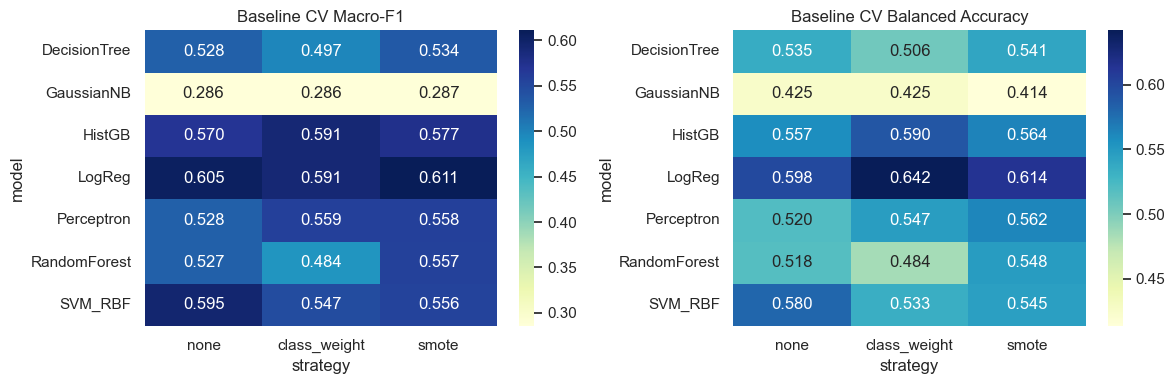

Selected strategy per model (by CV macro-F1): {'LogReg': 'smote', 'Perceptron': 'class_weight', 'GaussianNB': 'smote', 'DecisionTree': 'smote', 'SVM_RBF': 'none', 'RandomForest': 'smote', 'HistGB': 'class_weight'}


In [6]:
def cv_oof(make_est, X, y, groups, cv):
    y = np.asarray(y)
    oof = np.zeros((len(X), K))
    rows = []
    for _, (tr, va) in enumerate(cv.split(X, y, groups)):
        est = clone(make_est())
        est.fit(X.iloc[tr], y[tr])
        full = np.zeros((len(va), K))
        full[:, est.classes_] = est.predict_proba(X.iloc[va])
        oof[va] = full
        rows.append(all_metrics(y[va], full))
    return oof, pd.DataFrame(rows)


baseline_folds, baseline_rows = {}, []
for mname in MODEL_NAMES:
    for strat in STRATEGIES:
        t0 = time.time()
        _, fm = cv_oof(lambda m=mname, s=strat: make_pipe(m, s), X_train, y_train, g_train, cv_outer)
        baseline_folds[(mname, strat)] = fm
        baseline_rows.append(dict(
            model=mname,
            strategy=strat,
            **fm.mean().add_suffix("_mean").to_dict(),
            f1_macro_std=fm["f1_macro"].std(),
            bal_acc_std=fm["balanced_acc"].std(),
        ))
        print(
            f"{mname:13s} {strat:13s} f1_macro={fm['f1_macro'].mean():.3f}+/-{fm['f1_macro'].std():.3f} "
            f"bal_acc={fm['balanced_acc'].mean():.3f} ({time.time()-t0:.1f}s)"
        )

baseline = pd.DataFrame(baseline_rows)
pivot = baseline.pivot(index="model", columns="strategy", values="f1_macro_mean")[STRATEGIES]
pivot_bal = baseline.pivot(index="model", columns="strategy", values="balanced_acc_mean")[STRATEGIES]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax[0])
ax[0].set_title("Baseline CV Macro-F1")
sns.heatmap(pivot_bal, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax[1])
ax[1].set_title("Baseline CV Balanced Accuracy")
plt.tight_layout()
plt.show()

BEST_STRATEGY = {m: pivot.loc[m].idxmax() for m in MODEL_NAMES}
print("Selected strategy per model (by CV macro-F1):", BEST_STRATEGY)


## 5. Experiment B – Hyperparameter Tuning (Grouped CV, Scoring = `f1_macro`)


In [7]:
searches = {}
for mname in MODEL_NAMES:
    t0 = time.time()
    est = make_pipe(mname, BEST_STRATEGY[mname])
    rs = RandomizedSearchCV(
        est,
        MODELS[mname]["space"],
        n_iter=N_ITER,
        scoring="f1_macro",
        cv=StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED),
        random_state=SEED,
        n_jobs=N_JOBS,
        refit=True,
        error_score=np.nan,
    )
    rs.fit(X_train, y_train, groups=g_train)
    searches[mname] = rs
    print(
        f"{mname:13s} tuned CV f1_macro={rs.best_score_:.3f} | "
        f"baseline={pivot.loc[mname, BEST_STRATEGY[mname]]:.3f} | {time.time()-t0:.1f}s"
    )

tuning_summary = pd.DataFrame({
    m: dict(
        strategy=BEST_STRATEGY[m],
        baseline_cv_f1=pivot.loc[m, BEST_STRATEGY[m]],
        tuned_cv_f1=searches[m].best_score_,
        best_params=json.dumps({
            k: (float(v) if isinstance(v, (np.floating, float)) else v)
            for k, v in searches[m].best_params_.items()
        }, default=str)
    )
    for m in MODEL_NAMES
}).T
tuning_summary


LogReg        tuned CV f1_macro=0.614 | baseline=0.611 | 77.6s
Perceptron    tuned CV f1_macro=0.568 | baseline=0.559 | 13.9s
GaussianNB    tuned CV f1_macro=0.301 | baseline=0.287 | 69.1s
DecisionTree  tuned CV f1_macro=0.553 | baseline=0.534 | 70.7s
SVM_RBF       tuned CV f1_macro=0.568 | baseline=0.595 | 77.0s
RandomForest  tuned CV f1_macro=0.578 | baseline=0.557 | 201.2s
HistGB        tuned CV f1_macro=0.618 | baseline=0.591 | 316.6s


,strategy,baseline_cv_f1,tuned_cv_f1,best_params
LogReg,smote,0.610897,0.613797,"{""clf__C"": 0.4205156450913872}"
Perceptron,class_weight,0.558645,0.567616,"{""clf__estimator__alpha"": 0.001256315277393866..."
GaussianNB,smote,0.287404,0.301399,"{""clf__var_smoothing"": 7.072114131472235e-07}"
DecisionTree,smote,0.533873,0.553204,"{""clf__criterion"": ""entropy"", ""clf__max_depth""..."
SVM_RBF,none,0.594835,0.568342,"{""clf__C"": 11.290133559092672, ""clf__gamma"": 0..."
RandomForest,smote,0.557376,0.577528,"{""clf__max_depth"": 12, ""clf__max_features"": 0...."
HistGB,class_weight,0.591383,0.6178,"{""clf__l2_regularization"": 0.00420798866960663..."


## 6. Tuned CV Comparison & Friedman Statistical Test


In [8]:
tuned_oof, tuned_folds = {}, {}
for m in MODEL_NAMES:
    oof, fm = cv_oof(lambda m=m: searches[m].best_estimator_, X_train, y_train, g_train, cv_outer)
    tuned_oof[m], tuned_folds[m] = oof, fm

cv_table = pd.DataFrame({m: tuned_folds[m].mean() for m in MODEL_NAMES}).T
print("=== Tuned Models – Grouped CV Mean Metrics ===")
print(cv_table[["accuracy", "balanced_acc", "f1_macro", "mcc", "roc_auc_ovr_macro", "pr_auc_macro", "log_loss"]].round(3))

fold_f1 = pd.DataFrame({m: tuned_folds[m]["f1_macro"].values for m in MODEL_NAMES})
stat, pval = friedmanchisquare(*[fold_f1[m] for m in MODEL_NAMES])
print(f"Friedman test across models on fold macro-F1: chi2={stat:.3f}, p={pval:.4f}")

BEST_MODEL = cv_table["f1_macro"].idxmax()
print("Selected BEST_MODEL on CV macro-F1:", BEST_MODEL)


=== Tuned Models – Grouped CV Mean Metrics ===
              accuracy  balanced_acc  f1_macro    mcc  roc_auc_ovr_macro  \
LogReg           0.733         0.617     0.614  0.634              0.920   
Perceptron       0.728         0.554     0.568  0.624              0.905   
GaussianNB       0.408         0.425     0.301  0.309              0.802   
DecisionTree     0.668         0.563     0.553  0.552              0.819   
SVM_RBF          0.733         0.576     0.590  0.632              0.917   
RandomForest     0.717         0.592     0.578  0.612              0.908   
HistGB           0.707         0.630     0.618  0.604              0.911   

              pr_auc_macro  log_loss  
LogReg               0.683     0.737  
Perceptron           0.663     0.843  
GaussianNB           0.419    16.845  
DecisionTree         0.538     5.410  
SVM_RBF              0.692     0.731  
RandomForest         0.651     0.788  
HistGB               0.665     0.846  
Friedman test across models on f

## 7. Experiment C – Held-Out Test Evaluation, Per-Class Performance & Confusion Matrix


=== Held-Out Test Metrics ===
              accuracy  balanced_acc  f1_macro  f1_weighted  precision_macro  recall_macro    mcc  kappa  top2_acc  log_loss  brier    ece  roc_auc_ovr_macro  pr_auc_macro  roc_auc_ovo_macro  recall_SCC  recall_MEL  cancer_sensitivity  cancer_specificity  cancer_auc  cancer_pr_auc
LogReg           0.743         0.637     0.605        0.742            0.615         0.637  0.643  0.642     0.898     0.671  0.353  0.038              0.926         0.696              0.925       0.176       0.625               0.908               0.894       0.967          0.958
Perceptron       0.777         0.584     0.600        0.746            0.637         0.584  0.686  0.675     0.892     0.800  0.403  0.187              0.904         0.680              0.898       0.000       0.375               0.926               0.870       0.967          0.956
GaussianNB       0.380         0.369     0.265        0.375            0.501         0.369  0.274  0.241     0.745    18.269

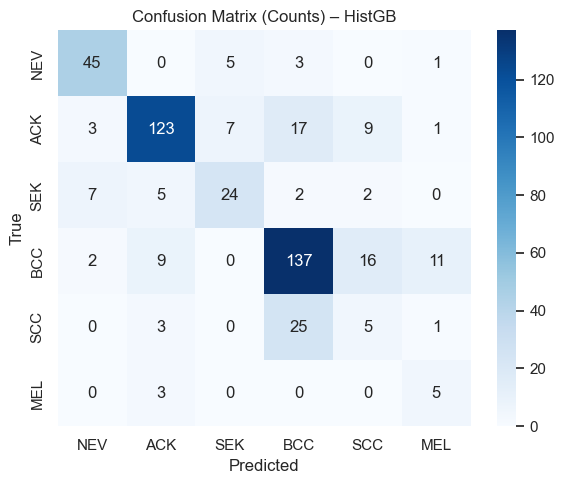

In [9]:
test_proba, test_pred = {}, {}
for m in MODEL_NAMES:
    est = searches[m].best_estimator_
    full = np.zeros((len(X_test), K))
    full[:, est.classes_] = est.predict_proba(X_test)
    test_proba[m], test_pred[m] = full, full.argmax(1)

test_table = pd.DataFrame({m: all_metrics(y_test, test_proba[m]) for m in MODEL_NAMES}).T
print("=== Held-Out Test Metrics ===")
print(test_table.round(3).to_string())

per_class = {m: per_class_table(y_test, test_proba[m]) for m in MODEL_NAMES}
print(f"\n=== Per-Class Test Metrics for {BEST_MODEL} ===")
print(per_class[BEST_MODEL].round(3))

cm_best = confusion_matrix(y_test, test_pred[BEST_MODEL], labels=CLASSES)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_best, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS)
plt.title(f"Confusion Matrix (Counts) – {BEST_MODEL}")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()


## 8. Experiment D – Patient-Level Bootstrap CIs, Permutation Importance, Learning Curve & Saving


=== Patient-Level Bootstrap 95% CIs (Test Set) ===
metric                    accuracy          balanced_acc              f1_macro                   mcc            recall_MEL
model                                                                                                                     
DecisionTree  0.701 [0.649, 0.750]  0.557 [0.473, 0.649]  0.548 [0.474, 0.631]  0.585 [0.518, 0.652]  0.361 [0.000, 0.800]
GaussianNB    0.381 [0.331, 0.430]  0.367 [0.291, 0.453]  0.264 [0.219, 0.311]  0.275 [0.223, 0.323]  0.361 [0.000, 0.800]
HistGB        0.720 [0.671, 0.764]  0.626 [0.538, 0.709]  0.586 [0.520, 0.658]  0.615 [0.553, 0.674]  0.625 [0.181, 1.000]
LogReg        0.743 [0.699, 0.785]  0.637 [0.544, 0.722]  0.601 [0.539, 0.668]  0.643 [0.583, 0.701]  0.625 [0.181, 1.000]
Perceptron    0.778 [0.731, 0.822]  0.582 [0.504, 0.672]  0.592 [0.511, 0.672]  0.686 [0.624, 0.748]  0.361 [0.000, 0.800]
RandomForest  0.743 [0.698, 0.789]  0.578 [0.493, 0.661]  0.555 [0.494, 0.623]  0.639 [0

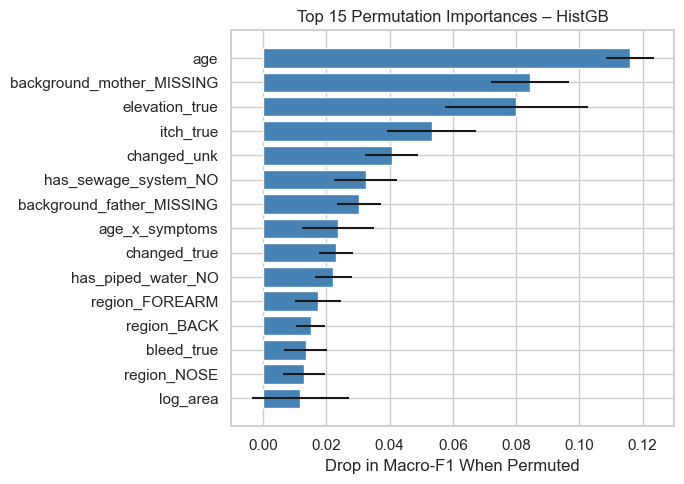

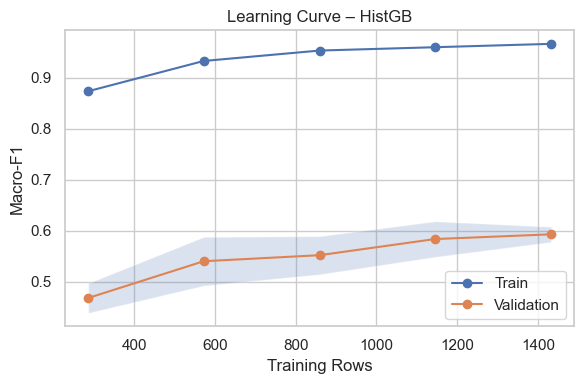


=== Classification Report (HistGB on Test Set) ===
              precision    recall  f1-score   support

         NEV       0.79      0.83      0.81        54
         ACK       0.86      0.77      0.81       160
         SEK       0.67      0.60      0.63        40
         BCC       0.74      0.78      0.76       175
         SCC       0.16      0.15      0.15        34
         MEL       0.26      0.62      0.37         8

    accuracy                           0.72       471
   macro avg       0.58      0.63      0.59       471
weighted avg       0.73      0.72      0.72       471

Saved all supervised evaluation artifacts to: C:\Users\Administrator\Desktop\skin-project\Output\04_supervised_eval


In [10]:
pats = np.unique(g_test)
idx_by_patient = {p: np.where(g_test == p)[0] for p in pats}
rng = np.random.default_rng(SEED)

BOOT_METRICS = ["accuracy", "balanced_acc", "f1_macro", "mcc", "recall_MEL"]
boot = {m: {k: [] for k in BOOT_METRICS} for m in MODEL_NAMES}

for _ in range(N_BOOT):
    sampled_pats = rng.choice(pats, size=len(pats), replace=True)
    idx = np.concatenate([idx_by_patient[p] for p in sampled_pats])
    yt = y_test[idx]
    pres = np.unique(yt)
    for m in MODEL_NAMES:
        pr = test_pred[m][idx]
        boot[m]["accuracy"].append(accuracy_score(yt, pr))
        boot[m]["balanced_acc"].append(balanced_accuracy_score(yt, pr))
        boot[m]["f1_macro"].append(f1_score(yt, pr, labels=pres, average="macro", zero_division=0))
        boot[m]["mcc"].append(matthews_corrcoef(yt, pr))
        boot[m]["recall_MEL"].append(((pr == 5) & (yt == 5)).sum() / (yt == 5).sum() if (yt == 5).any() else np.nan)

ci_rows = []
for m in MODEL_NAMES:
    for k_m in BOOT_METRICS:
        vals = np.array(boot[m][k_m], dtype=float)
        ci_rows.append({
            "model": m,
            "metric": k_m,
            "mean": float(np.nanmean(vals)),
            "ci_low": float(np.nanpercentile(vals, 2.5)),
            "ci_high": float(np.nanpercentile(vals, 97.5)),
        })
ci_df = pd.DataFrame(ci_rows)
ci_fmt = ci_df.assign(
    fmt=lambda d: d.apply(lambda r: f"{r['mean']:.3f} [{r['ci_low']:.3f}, {r['ci_high']:.3f}]", axis=1)
).pivot(index="model", columns="metric", values="fmt")[BOOT_METRICS]
print("=== Patient-Level Bootstrap 95% CIs (Test Set) ===")
print(ci_fmt.to_string())

best_est = searches[BEST_MODEL].best_estimator_
pi = permutation_importance(best_est, X_test, y_test, scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=N_JOBS)
imp_df = pd.DataFrame({"importance": pi.importances_mean, "std": pi.importances_std}, index=FEATS).sort_values("importance", ascending=False)
top15 = imp_df.head(15).iloc[::-1]

plt.figure(figsize=(7, 5))
plt.barh(top15.index, top15["importance"], xerr=top15["std"], color="steelblue")
plt.xlabel("Drop in Macro-F1 When Permuted")
plt.title(f"Top 15 Permutation Importances – {BEST_MODEL}")
plt.tight_layout()
plt.show()

sizes, tr_sc, va_sc = learning_curve(
    clone(best_est),
    X_train,
    y_train,
    groups=g_train,
    scoring="f1_macro",
    cv=StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED),
    train_sizes=np.linspace(0.2, 1.0, 5),
    n_jobs=N_JOBS,
)
plt.figure(figsize=(6, 4))
plt.plot(sizes, tr_sc.mean(1), "o-", label="Train")
plt.plot(sizes, va_sc.mean(1), "o-", label="Validation")
plt.fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
plt.xlabel("Training Rows")
plt.ylabel("Macro-F1")
plt.title(f"Learning Curve – {BEST_MODEL}")
plt.legend()
plt.tight_layout()
plt.show()

print(f"\n=== Classification Report ({BEST_MODEL} on Test Set) ===")
print(classification_report(y_test, test_pred[BEST_MODEL], labels=CLASSES, target_names=LABELS, zero_division=0))

if SAVE:
    baseline.to_csv(OUT_DIR / "A_baseline_cv.csv", index=False)
    tuning_summary.to_csv(OUT_DIR / "B_tuning_summary.csv")
    cv_table.to_csv(OUT_DIR / "tuned_cv_metrics.csv")
    test_table.to_csv(OUT_DIR / "C_test_metrics.csv")
    ci_df.to_csv(OUT_DIR / "D_bootstrap_ci.csv", index=False)
    imp_df.to_csv(OUT_DIR / "permutation_importance.csv")
    pd.concat(per_class, names=["model", "class"]).to_csv(OUT_DIR / "per_class_test.csv")
    for m in MODEL_NAMES:
        joblib.dump(searches[m].best_estimator_, OUT_DIR / f"model_{m}.joblib")
    print("Saved all supervised evaluation artifacts to:", OUT_DIR.resolve())
